# Parte 6 (opcional) – ¿Le gana una regresión logística al BG/NBD?

**Autor:** Herman Andrés Echeverría Rojas · Grupo 1

**Declaración de uso de IA:** se utilizó Claude (Anthropic) como herramienta de apoyo para comprender lo que pedía cada inciso del enunciado y como asistencia al escribir y depurar el código. El análisis, la verificación de resultados y su interpretación fueron revisados por el autor.

**Referencias principales**

- Fader, P. S., Hardie, B. G. S. y Lee, K. L. (2005). "Counting Your Customers" the Easy Way: An Alternative to the Pareto/NBD Model. *Marketing Science*, 24(2), 275–284.
- Documentación de scikit-learn: `LogisticRegression`, `StratifiedKFold`, `Pipeline` y `brier_score_loss`.

En la Parte 4, Gregorio encontró que $P(Z = 1)$ del BG/NBD no ordena a los clientes mucho mejor que la recencia sola. Si lo que queremos es $P(Z = 1)$, una regresión logística con $x$, $t_x$ y $T$ es la respuesta obvia de cualquier científico de datos. Aquí la ponemos a competir (6.1) y después revisamos si la competencia fue justa (6.2–6.4). Las funciones del BG/NBD son las de `src/bgnbd.py` (`p_compra`, de Gregorio) y los parámetros se leen de `resultados/params_cdnow.json`.

In [1]:
import sys, json
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from datos import cargar_cdnow, resumen_clientes
from bgnbd import p_compra

trans = cargar_cdnow("../data/CDNOW_sample.txt")
params = json.load(open("../resultados/params_cdnow.json"))
VARIABLES = ["x", "tx", "T"]

# Calibración hasta el 30 sep 1997 y holdout de 39 semanas, como en las Partes 3 y 4
res = resumen_clientes(trans, "1997-09-30", "1998-06-30")
z = (res["x_star"] >= 1).astype(int).values
res["p_compra"] = p_compra(39, res["x"], res["tx"], res["T"], params)

print(f"{len(res)} clientes; tasa base de Z = {z.mean():.3f}")
print("Parámetros del BG/NBD:", {k: round(v, 4) for k, v in params.items()})

2357 clientes; tasa base de Z = 0.290
Parámetros del BG/NBD: {'r': 0.2426, 'alpha': 4.4136, 'a': 0.7929, 'b': 2.4259}


In [2]:
def nueva_logistica():
    # Sin penalización, como pide el enunciado. El escalador va dentro del pipeline para que,
    # en la validación cruzada, la media y la DE se calculen solo con los pliegues de entrenamiento.
    return make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=1000))


def metricas(y, prob):
    return {"AUC": roc_auc_score(y, prob), "Brier": brier_score_loss(y, prob),
            "prob. promedio": np.mean(prob), "tasa real": np.mean(y)}


def tabla_deciles(prob, y):
    # rank(method="first") rompe empates para que cada decil tenga el mismo número de clientes
    decil = pd.qcut(pd.Series(prob).rank(method="first"), 10, labels=range(1, 11))
    g = pd.DataFrame({"prob": np.asarray(prob), "y": np.asarray(y)}).groupby(decil.values, observed=True)
    return pd.DataFrame({"prob. promedio": g["prob"].mean(), "fracción que compró": g["y"].mean()}).rename_axis("decil")


def grafica_calibracion(tablas, titulo, archivo):
    colores = {"Logística": "#4C72B0", "BG/NBD": "#C44E52"}
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.plot([0, 1], [0, 1], color="gray", ls=":", label="Calibración perfecta")
    for nombre, t in tablas.items():
        ax.plot(t["prob. promedio"], t["fracción que compró"], marker="o",
                color=colores.get(nombre.split(" ")[0], None), label=nombre)
    ax.set(title=titulo, xlabel="Probabilidad promedio del decil", ylabel="Fracción que compró",
           xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.savefig(f"../figs/{archivo}", dpi=150)
    plt.show()

## 6.1 La comparación ingenua

Se ajusta una regresión logística de $Z_i$ contra $x$, $t_x$ y $T$ estandarizados y sin penalización (`LogisticRegression(C=np.inf)`). Se evalúa con validación cruzada estratificada de 5 pliegues **sobre clientes**, repetida con 20 semillas (las 20 primeras de la lista de la propuesta), es decir, 100 particiones.

En cada pliegue de prueba se calculan el AUC y el Brier score de la logística y de $P(Z = 1)$ del BG/NBD (inciso 4.3) **sobre los mismos clientes**. El BG/NBD usa los mismos parámetros en todos los pliegues: se estimó solo con $(x, t_x, T)$ de calibración y nunca vio una etiqueta $Z$, así que no hay nada que reajustar.

In [3]:
SEMILLAS = [77785, 14045, 114526, 85967, 85603, 2452, 175326, 32532, 155374, 101914,
            37119, 190629, 22054, 21663, 77709, 21226, 49984, 119397, 169546, 6120]
X = res[VARIABLES].values
pz = res["p_compra"].values

filas, oof = [], np.zeros((len(SEMILLAS), len(z)))
for i, semilla in enumerate(SEMILLAS):
    for entrena, prueba in StratifiedKFold(5, shuffle=True, random_state=semilla).split(X, z):
        prob = nueva_logistica().fit(X[entrena], z[entrena]).predict_proba(X[prueba])[:, 1]
        oof[i, prueba] = prob
        filas.append({"semilla": semilla,
                      "AUC logística": roc_auc_score(z[prueba], prob),
                      "AUC BG/NBD": roc_auc_score(z[prueba], pz[prueba]),
                      "Brier logística": brier_score_loss(z[prueba], prob),
                      "Brier BG/NBD": brier_score_loss(z[prueba], pz[prueba])})
cv = pd.DataFrame(filas)

resumen_cv = pd.DataFrame({"media": cv.drop(columns="semilla").mean(), "DE": cv.drop(columns="semilla").std()})
print(f"La logística tiene mayor AUC en {(cv['AUC logística'] > cv['AUC BG/NBD']).mean():.0%} de los 100 pliegues "
      f"y menor Brier en {(cv['Brier logística'] < cv['Brier BG/NBD']).mean():.0%}.")
resumen_cv.round(4)

La logística tiene mayor AUC en 93% de los 100 pliegues y menor Brier en 94%.


,media,DE
AUC logística,0.7791,0.0217
AUC BG/NBD,0.7570,0.0224
Brier logística,0.1562,0.0077
Brier BG/NBD,0.1612,0.0064


> **¿Quién gana la comparación ingenua?**

La logística, y no por suerte. Su AUC promedio es ≈ 0.779 frente a ≈ 0.757 del BG/NBD, y su Brier score es ≈ 0.156 frente a ≈ 0.161. Gana en AUC en el 93 % de los 100 pliegues y en Brier en el 94 %, así que la diferencia no se explica por la partición. La DE entre pliegues (≈ 0.02 en AUC) es del mismo orden que la diferencia, pero como en cada pliegue los dos modelos se evalúan sobre los mismos clientes, lo que importa es que la logística sale arriba casi siempre.

### Curva de calibración y coeficientes

Para la calibración se usan las predicciones *fuera de pliegue*: cada cliente recibe la probabilidad de la logística que no lo vio al entrenar, promediada sobre las 20 repeticiones.

Logística (fuera de pliegue)                     BG/NBD P(Z = 1)  \
                    prob. promedio fracción que compró  prob. promedio   
decil                                                                    
1                            0.108               0.102           0.122   
2                            0.125               0.123           0.150   
3                            0.139               0.119           0.155   
4                            0.154               0.144           0.160   
5                            0.171               0.165           0.165   
6                            0.187               0.183           0.170   
7                            0.229               0.242           0.181   
8                            0.395               0.477           0.304   
9                            0.597               0.572           0.467   
10                           0.796               0.775           0.742   

                           
      fracción que compró  
decil                      
1                   0.199  
2                   0.097  
3                   0.136  
4                   0.114  
5                   0.161  
6                   0.170  
7                   0.237  
8                   0.438  
9                   0.534  
10                  0.814

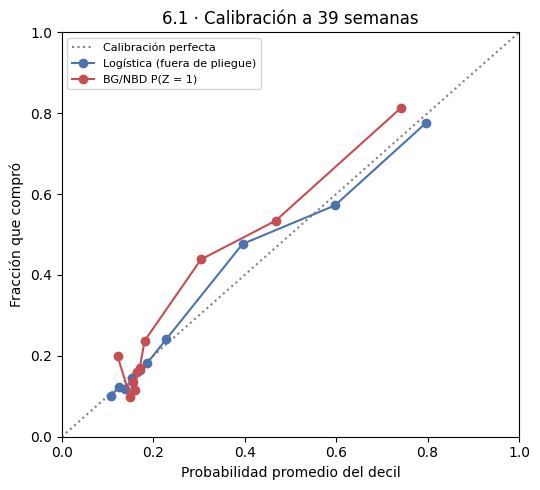

In [4]:
prob_oof = oof.mean(axis=0)
cal_61 = {"Logística (fuera de pliegue)": tabla_deciles(prob_oof, z), "BG/NBD P(Z = 1)": tabla_deciles(pz, z)}
display(pd.concat(cal_61, axis=1).round(3))
grafica_calibracion(cal_61, "6.1 · Calibración a 39 semanas", "parte6_calibracion_ingenua.png")

In [5]:
logistica_39 = nueva_logistica().fit(X, z)
coef = pd.DataFrame({
    "coeficiente (estandarizado)": logistica_39[-1].coef_[0],
    "razón de momios por 1 DE": np.exp(logistica_39[-1].coef_[0]),
    "DE de la variable (semanas o compras)": logistica_39[0].scale_,
}, index=VARIABLES)
print(f"Intercepto: {logistica_39[-1].intercept_[0]:.3f}")
display(coef.round(3))
res[VARIABLES].corr().round(2)

Intercepto: -1.035


,coeficiente (estandarizado),razón de momios por 1 DE,DE de la variable (semanas o compras)
x,0.465,1.591,2.190
tx,0.795,2.215,10.729
T,-0.231,0.794,3.326


,x,tx,T
x,1.00,0.66,0.05
tx,0.66,1.00,0.07
T,0.05,0.07,1.00


> **Calibración e interpretación de los coeficientes**

**Calibración.** Fuera de pliegue, la logística está muy bien calibrada a 39 semanas: en los diez deciles su probabilidad promedio y la fracción que compró difieren en menos de 0.03, salvo el decil 8 (0.40 contra 0.48). El BG/NBD, en cambio, subestima a los mejores clientes (deciles 8 a 10: predice 0.30, 0.47 y 0.74; compraron 0.44, 0.53 y 0.81), lo mismo que Gregorio encontró en 4.5. No es raro que la logística esté mejor calibrada: se entrenó justamente para reproducir la frecuencia de $Z$ a 39 semanas.

**Coeficientes** (variables estandarizadas, así que son comparables entre sí):

- **$t_x$ pesa más** (+0.80; cada DE de recencia, ≈ 10.7 semanas, multiplica los momios de comprar por ≈ 2.2). Un cliente cuya última compra fue reciente probablemente sigue vivo. Es la misma conclusión de 4.5: la recencia sola ya ordena muy bien.
- **$x$ tiene signo positivo** (+0.47; momios × 1.6 por DE). Con la recencia fija, quien compró más veces tiene mayor tasa de compra $\lambda$.
- **$T$ tiene signo negativo** (−0.23; momios × 0.79 por DE). Con $x$ y $t_x$ fijos, un $T$ mayor significa que el cliente lleva más tiempo sin comprar desde $t_x$ y que esas $x$ compras se repartieron en más tiempo: menor tasa y más probabilidad de haber muerto. El BG/NBD dice lo mismo: $P(\text{vivo})$ baja cuando $(\alpha + T)/(\alpha + t_x)$ crece.

Los signos coinciden con lo que predice el BG/NBD. $x$ y $t_x$ están correlacionados (0.66), así que sus coeficientes por separado deben leerse con cuidado; $T$ casi no se correlaciona con ninguna (≈ 0.05).

**Veredicto ingenuo:** la logística gana en ordenar y en calibración. Pero falta revisar si la competencia fue justa.

## 6.2 ¿Fue justa?

No. La logística de 6.1 aprendió con **etiquetas del holdout** de otros clientes: para entrenarla usamos si cada cliente compró entre octubre de 1997 y junio de 1998. Aunque la validación cruzada separa clientes, los pliegues de entrenamiento siguen conteniendo información del futuro: cómo se comportó *esta misma cohorte* en *ese mismo periodo*, con su estacionalidad (incluida la Navidad de 1997) y su ritmo de abandono. El BG/NBD, en cambio, nunca vio nada posterior al 30 de septiembre.

**El 30 de septiembre de 1997, ¿con qué etiquetas se podía entrenar la logística?** Solo con etiquetas de un periodo **anterior**: calcular $(x, t_x, T)$ en una fecha más temprana (por ejemplo, el 1 de julio) y usar como etiqueta si el cliente compró entre esa fecha y el 30 de septiembre. Así las características y las etiquetas existían el 30 de septiembre, pero el modelo se entrena con clientes "más jóvenes" y para un horizonte más corto que el que se quiere predecir. Esa es la versión honesta de 6.3.

**Relación con la tarea de series de tiempo.** Es la misma **fuga de información** (*data leakage*) que en series de tiempo aparece al validar con particiones aleatorias en vez de respetar el orden temporal: el modelo usa, al entrenar, información que no existiría en el momento de pronosticar, y la evaluación sale optimista. En series de tiempo se evita con validación hacia adelante (*rolling origin*): entrenar solo con el pasado y evaluar en el futuro. Separar por clientes no basta cuando todos los clientes comparten el mismo periodo futuro; hay que separar **por tiempo**.

## 6.3 La versión honesta

Replicamos lo que sí se podía hacer el 30 de septiembre de 1997. Para un horizonte de $h$ semanas:

1. **Entrenamiento:** $(x, t_x, T)$ calculados con los datos hasta $h$ semanas antes del 30 de septiembre, y como etiqueta si el cliente compró entre ese corte y el 30 de septiembre. Todo esto ya era observable el 30 de septiembre.
2. **Aplicación:** el modelo entrenado se aplica a los $(x, t_x, T)$ del 30 de septiembre para predecir quién compra en las primeras $h$ semanas del holdout.
3. **Comparación:** contra $P(Z = 1)$ del BG/NBD con $\tau = h$, con los mismos parámetros de siempre, que también se estimaron solo con datos hasta el 30 de septiembre.

`resumen_clientes` de Sofía recibe las fechas de corte como parámetro, así que construye las dos tablas sin código nuevo.

In [6]:
def version_honesta(corte_entrenamiento, fin_aplicacion, h):
    ent = resumen_clientes(trans, corte_entrenamiento, "1997-09-30")
    apl = resumen_clientes(trans, "1997-09-30", fin_aplicacion)
    y_ent, y_apl = (ent["x_star"] >= 1).astype(int), (apl["x_star"] >= 1).astype(int)

    modelo = nueva_logistica().fit(ent[VARIABLES], y_ent)
    prob_log = modelo.predict_proba(apl[VARIABLES])[:, 1]
    prob_bg = p_compra(h, apl["x"], apl["tx"], apl["T"], params)

    tabla = pd.DataFrame({"Logística honesta": metricas(y_apl, prob_log), "BG/NBD": metricas(y_apl, prob_bg)}).T
    rangos = pd.DataFrame({"T mínimo": [ent["T"].min(), apl["T"].min()], "T máximo": [ent["T"].max(), apl["T"].max()],
                           "tasa de compra": [y_ent.mean(), y_apl.mean()]},
                          index=[f"entrenamiento (corte {corte_entrenamiento})", "aplicación (corte 1997-09-30)"])
    return tabla, rangos, modelo


# 13 semanas: características al 1 jul, etiquetas del 2 jul al 30 sep; se predice del 1 oct al 30 dic
tabla_13, rangos_13, logistica_13 = version_honesta("1997-07-01", "1997-12-30", 13)
display(tabla_13.round(4))
rangos_13.round(2)

,AUC,Brier,prob. promedio,tasa real
Logística honesta,0.7921,0.1124,0.1377,0.1706
BG/NBD,0.7845,0.1102,0.1537,0.1706


,T mínimo,T máximo,tasa de compra
entrenamiento (corte 1997-07-01),14.0,25.86,0.17
aplicación (corte 1997-09-30),27.0,38.86,0.17


> **13 semanas: ¿quién gana cuando la competencia es honesta?**

La ventaja de la logística casi desaparece. En AUC sigue ligeramente arriba (≈ 0.792 contra ≈ 0.785), pero ahora el **BG/NBD tiene mejor Brier** (≈ 0.110 contra ≈ 0.112) y su probabilidad promedio está más cerca de la tasa real: el BG/NBD predice en promedio 0.154 y la logística 0.138, cuando la tasa real es 0.171. La logística honesta subestima cuántos clientes van a comprar en ≈ 19 %.

**¿Qué le estamos pidiendo a la logística?** Que **extrapole**. Se entrenó con clientes cuyo $T$ estaba entre 14 y 26 semanas y se aplica a clientes con $T$ entre 27 y 39: ningún cliente de aplicación se parece en antigüedad a los de entrenamiento. El coeficiente negativo de $T$ se aprendió en un rango y se usa en otro, y como el modelo es lineal en el logit, empuja las probabilidades hacia abajo más de lo que corresponde. El BG/NBD no tiene ese problema: su fórmula de $P(Z = 1)$ vale para cualquier $T$ y cualquier $\tau$, porque viene de la historia de comportamiento y no de una relación ajustada en un rango.

### Horizonte de 26 semanas

Características al 1 de abril, etiquetas del 2 de abril al 30 de septiembre, y predicción de las primeras 26 semanas del holdout (1 de octubre de 1997 al 31 de marzo de 1998).

In [7]:
tabla_26, rangos_26, logistica_26 = version_honesta("1997-04-01", "1998-03-31", 26)
display(tabla_26.round(4))
display(rangos_26.round(2))

pd.DataFrame({f"logística {h} semanas": m[-1].coef_[0] for h, m in
              ((39, logistica_39), (13, logistica_13), (26, logistica_26))}, index=VARIABLES).round(3)

,AUC,Brier,prob. promedio,tasa real
Logística honesta,0.7849,0.1559,0.2003,0.2512
BG/NBD,0.7615,0.1475,0.2203,0.2512


,T mínimo,T máximo,tasa de compra
entrenamiento (corte 1997-04-01),1.0,12.86,0.31
aplicación (corte 1997-09-30),27.0,38.86,0.25


,logística 39 semanas,logística 13 semanas,logística 26 semanas
x,0.465,0.546,0.597
tx,0.795,0.459,0.267
T,-0.231,-0.244,-0.330


> **26 semanas: la extrapolación es más grande y el resultado empeora**

Con 26 semanas el entrenamiento usa clientes con $T$ entre 1 y 13 semanas (recién llegados) y se aplica a $T$ entre 27 y 39. La distancia entre los dos rangos es todavía mayor, y se nota:

- El **BG/NBD gana claramente en Brier** (≈ 0.148 contra ≈ 0.156) y vuelve a estar más cerca del nivel real (0.220 contra 0.200, con tasa real de 0.251).
- La logística conserva un AUC algo mayor (≈ 0.785 contra ≈ 0.762): para *ordenar*, $x$ y $t_x$ siguen funcionando aunque el modelo se aplique fuera de su rango.
- Además, la tasa de compra en el entrenamiento (0.31) es distinta de la de aplicación (0.25): a los recién llegados de la primavera les falta "envejecer". La logística aprende la relación de un tipo de cliente y se aplica a otro.

Los coeficientes cambian con el horizonte: el peso de $t_x$ baja de 0.80 (39 semanas) a 0.46 (13) y 0.27 (26), y el de $T$ se vuelve más negativo. En los cortes tempranos los clientes tienen poca historia y $t_x$ informa menos. No hay un único modelo logístico: hay uno por horizonte y por fecha de corte.

**Conclusión de 6.3:** sin la fuga, la logística ordena un poco mejor, pero el BG/NBD da probabilidades más precisas, y su ventaja crece cuanto más tiene que extrapolar la logística.

## 6.4 Cambiar la pregunta

El gerente ahora quiere saber quién compra en las próximas **13** semanas, no en 39. Con el BG/NBD solo cambia $\tau$ en `p_compra`. La logística de 6.1 aprendió a predecir compra en 39 semanas; para responder la pregunta nueva habría que **volver a entrenarla con etiquetas de 13 semanas**, que el 30 de septiembre solo existen para un periodo anterior (es lo que hicimos en 6.3). Aquí la usamos tal cual, sin reentrenar, para ver qué pasa.

,AUC,Brier,prob. promedio,tasa real
Logística de 6.1 (39 semanas),0.7909,0.1284,0.2902,0.1706
BG/NBD con τ = 13,0.7845,0.1102,0.1537,0.1706


Logística de 6.1 usada a 13 semanas                      BG/NBD τ = 13  \
                           prob. promedio fracción que compró prob. promedio   
decil                                                                          
1                                   0.109               0.042          0.057   
2                                   0.125               0.059          0.065   
3                                   0.139               0.064          0.068   
4                                   0.154               0.047          0.071   
5                                   0.171               0.097          0.074   
6                                   0.187               0.106          0.077   
7                                   0.229               0.097          0.090   
8                                   0.395               0.264          0.169   
9                                   0.597               0.309          0.281   
10                                  0.796               0.619          0.583   

                           
      fracción que compró  
decil                      
1                   0.072  
2                   0.059  
3                   0.060  
4                   0.055  
5                   0.047  
6                   0.119  
7                   0.119  
8                   0.209  
9                   0.331  
10                  0.636

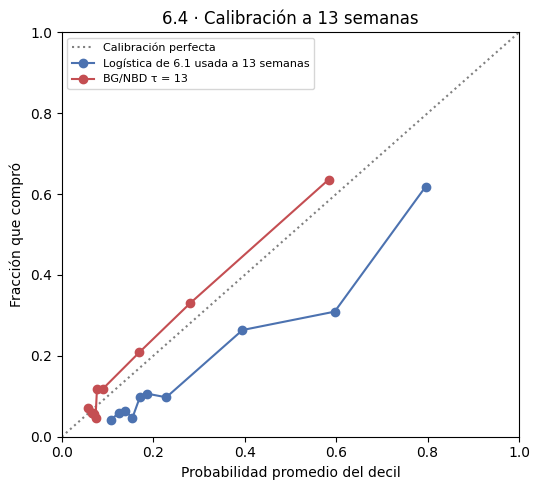

In [8]:
apl_13 = resumen_clientes(trans, "1997-09-30", "1997-12-30")
z_13 = (apl_13["x_star"] >= 1).astype(int).values
prob_log_39 = logistica_39.predict_proba(apl_13[VARIABLES].values)[:, 1]
prob_bg_13 = p_compra(13, apl_13["x"], apl_13["tx"], apl_13["T"], params)

display(pd.DataFrame({"Logística de 6.1 (39 semanas)": metricas(z_13, prob_log_39),
                      "BG/NBD con τ = 13": metricas(z_13, prob_bg_13)}).T.round(4))
cal_64 = {"Logística de 6.1 usada a 13 semanas": tabla_deciles(prob_log_39, z_13),
          "BG/NBD τ = 13": tabla_deciles(prob_bg_13, z_13)}
display(pd.concat(cal_64, axis=1).round(3))
grafica_calibracion(cal_64, "6.4 · Calibración a 13 semanas", "parte6_calibracion_13_semanas.png")

> **¿Qué pasó al usar la logística de 39 semanas para 13?**

Que ordena igual de bien pero **se equivoca de nivel**. Su AUC no cambia (≈ 0.791), porque el orden de los clientes por $x$ y $t_x$ es el mismo para cualquier horizonte. Pero predice en promedio 0.29, que es la tasa de compra a **39** semanas, cuando a 13 semanas compra el 0.17: **sobreestima en ≈ 70 %**. En la curva de calibración todos los deciles quedan por encima de la diagonal (por ejemplo, el decil 7 predice 0.23 y compró 0.10). Su Brier (≈ 0.128) es claramente peor que el del BG/NBD con $\tau = 13$ (≈ 0.110), que sigue calibrado sin reentrenar nada.

La logística aprendió "probabilidad de comprar en 39 semanas"; no sabe que el horizonte existe. Para responder la pregunta nueva hay que volver a entrenarla con etiquetas de 13 semanas, y el 30 de septiembre esas etiquetas solo existen para un periodo anterior, con el problema de extrapolación de 6.3. Al BG/NBD le basta con cambiar $\tau$.

## 6.5 Veredicto

In [9]:
pd.DataFrame({
    ("AUC", "logística"): [cv["AUC logística"].mean(), tabla_13.loc["Logística honesta", "AUC"],
                           tabla_26.loc["Logística honesta", "AUC"], roc_auc_score(z_13, prob_log_39)],
    ("AUC", "BG/NBD"): [cv["AUC BG/NBD"].mean(), tabla_13.loc["BG/NBD", "AUC"],
                        tabla_26.loc["BG/NBD", "AUC"], roc_auc_score(z_13, prob_bg_13)],
    ("Brier", "logística"): [cv["Brier logística"].mean(), tabla_13.loc["Logística honesta", "Brier"],
                             tabla_26.loc["Logística honesta", "Brier"], brier_score_loss(z_13, prob_log_39)],
    ("Brier", "BG/NBD"): [cv["Brier BG/NBD"].mean(), tabla_13.loc["BG/NBD", "Brier"],
                          tabla_26.loc["BG/NBD", "Brier"], brier_score_loss(z_13, prob_bg_13)],
}, index=["6.1 ingenua, 39 semanas (CV)", "6.3 honesta, 13 semanas", "6.3 honesta, 26 semanas",
          "6.4 logística de 39 usada a 13"]).round(4)

AUC             Brier        
                               logística  BG/NBD logística  BG/NBD
6.1 ingenua, 39 semanas (CV)      0.7791  0.7570    0.1562  0.1612
6.3 honesta, 13 semanas           0.7921  0.7845    0.1124  0.1102
6.3 honesta, 26 semanas           0.7849  0.7615    0.1559  0.1475
6.4 logística de 39 usada a 13    0.7909  0.7845    0.1284  0.1102

**¿Cuándo usaría la logística y cuándo el BG/NBD?**

Usaría la **logística** cuando la tarea es solo **ordenar** clientes para un horizonte fijo, con etiquetas de un periodo anterior comparable y una población que no cambia mucho entre entrenamiento y aplicación. Ejemplo: elegir a qué 10 % de una base ya madura mandarle una promoción el próximo trimestre, cuando el año pasado se hizo lo mismo. En ese caso ordena un poco mejor (AUC ≈ 0.78–0.79 contra ≈ 0.76–0.78), aunque la recencia sola ya hace casi el mismo trabajo (Parte 4).

Usaría el **BG/NBD** en casi todo lo demás:

- Cuando importan los **niveles** y no solo el orden. Sin fuga, sus probabilidades son más precisas (mejor Brier en 13 y 26 semanas).
- Cuando cambia el **horizonte**. El mismo ajuste sirve para 13, 26 o 39 semanas cambiando $\tau$; la logística de 39 semanas usada a 13 sobreestima en 70 %.
- Cuando se necesita el **total de la base**. Con $E[X(t)]$ y $E[Y(\tau)]$, el BG/NBD pronostica cuántas compras hará la cohorte, como en la Parte 3; la logística solo da $P(\text{al menos una compra})$ y no sirve para pronosticar volumen.
- Cuando **no hay etiquetas de un periodo anterior**: una cohorte nueva, una tienda nueva o la primera vez que se hace el análisis. La logística simplemente no se puede entrenar, y el BG/NBD se ajusta solo con $(x, t_x, T)$.

La comparación ingenua de 6.1 hacía ver ganadora a la logística porque entrenó con información del futuro. Corregida la fuga, la logística solo conserva una ventaja pequeña en ordenar; el BG/NBD es la herramienta más general y la única disponible cuando el futuro todavía no ha pasado.